# Análise das Falhas Unânimes do Super-Oráculo – Dataset IARA
### Notebook 25: Instâncias em que nenhum dos 16 especialistas acerta

No estudo de roteamento dinâmico (Gating, Notebook 24) sobre o dataset **IARA** (*Silva et al.*, IEEE Access 2025), o **Super-Oráculo** combina 16 especialistas (4 representações espectrais $\times$ 4 famílias de classificadores) e conta acerto quando **pelo menos um** dos 16 acerta. Ele usa o rótulo verdadeiro para escolher o especialista: **não é um sistema realizável**. Nos 10 folds do $5\times2\text{cv}$:
* **Índice SP:** 97,70 ± 0,75%
* **Acurácia Global (micro):** 97,48 ± 0,68%
* **Acurácia Balanceada:** 97,70 ± 0,74%

> **Referências de acaso.** Um oráculo de 16 preditores **uniformemente aleatórios** (4 classes) teria SP $= 1-(3/4)^{16} = 99,00\%$, e o esperado se os erros dos 16 especialistas fossem independentes é 99,996%. O valor observado fica abaixo de ambos: com 16 tentativas por áudio, um oráculo perto de 100% é esperado mesmo sem complementaridade real, e os erros dos especialistas são correlacionados. O SP do Super-Oráculo não é um "teto" de desempenho.

Em **6.229 das 6.390 avaliações de teste** (arquivo × fold) pelo menos um especialista acertou. O split do protocolo é por gravação (`ID`), não por navio: o mesmo navio pode ter gravações em treino e teste.

Nas outras **161 instâncias (2,52%)**, **todos os 16 especialistas erraram**. Como cada gravação aparece em vários folds de teste, essas 161 instâncias correspondem a **93 gravações distintas**: 91 gravações de **69 navios** e 2 gravações de *Background*.

### Objetivo deste Notebook:
1. **Identificar** cada uma dessas gravações cruzando o `ID` com os metadados do IARA (`iara.csv`: nome, tipo AIS, comprimento, estado do mar);
2. **Mostrar o que os 16 especialistas previram** em consenso e comparar com a classe real;
3. **Descrever** os descritores do sinal (potência RMS, razão de energia alta/baixa frequência, índice de modulação) dessas gravações em relação às medianas de cada classe;
4. Agrupar as falhas nos **4 principais grupos de confusão**.

In [1]:
import os
import sys
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

try:
    from IPython.display import display, HTML
except ImportError:
    display = print

for _p in ('.', 'src', 'notebooks', 'notebooks/src'):
    if os.path.exists(os.path.join(_p, 'iara_results.py')) and os.path.abspath(_p) not in sys.path:
        sys.path.insert(0, os.path.abspath(_p))
import gating_comum as G   # predições por arquivo dos 16 especialistas, meta-features e iara.csv

# Configuração de estilo visual (sem dependência externa de seaborn)
if 'seaborn-v0_8-whitegrid' in plt.style.available:
    plt.style.use('seaborn-v0_8-whitegrid')
elif 'seaborn-whitegrid' in plt.style.available:
    plt.style.use('seaborn-whitegrid')
else:
    plt.style.use('default')

plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.titlesize': 15,
    'figure.dpi': 120
})

print("Ambiente configurado com sucesso.")

Ambiente configurado com sucesso.


## 1. Carregamento dos Dados de Predição dos 16 Especialistas e Metadados do IARA

Carregamos os 10 folds de validação cruzada para as 4 famílias de modelos nas 4 representações:
* **Modelos:** Random Forest (RF), Multi-Layer Perceptron (MLP), Support Vector Machine (SVM Nyström RBF) e CNN 2D.
* **Representações:** MEL, LOFAR, HHT e DEMON.
* **Total:** $4 \times 4 = 16$ especialistas para cada áudio. A procedência de cada especialista (pipeline oficial ou script ad hoc, especialistas colapsados) está na Seção 3.1 do Notebook 24.

Cruzamos cada áudio com:
1. `src/iara/dataset_info/iara.csv` (nome do navio, comprimento, tipo AIS, estado do mar, vento e chuva);
2. `data/iara_processed/cache_gating_metafeatures.pkl` (7 descritores acústicos dos primeiros 10 s).

A predição de consenso é a classe mais votada entre os 16 (`Counter.most_common`; em empate, a do primeiro especialista na ordem RF, SVM, MLP, CNN × MEL, LOFAR, HHT, DEMON).

In [2]:
df_fail, total_evaluations = G.unanimous_failures()
ship_ids = df_fail['ship_id'].astype(str).str.strip()

print(f"Total de avaliações de teste (arquivo x fold, 10 folds 5x2cv): {total_evaluations}")
print(f"Instâncias em que TODOS os 16 especialistas erraram: {len(df_fail)} ({len(df_fail)/total_evaluations*100:.2f}%)")
print(f"  = {df_fail['file_id'].nunique()} gravações distintas; {ship_ids[ship_ids != '-'].nunique()} navios (Ship ID)")
print(f"  instâncias com empate na predição de consenso: {int(df_fail['empate_no_consenso'].sum())}")
print(f"Acertos do Super-Oráculo: {total_evaluations - len(df_fail)} ({((total_evaluations - len(df_fail))/total_evaluations)*100:.2f}%)")

sup = G.oracle(G.ALL16)
print(f"\nSuper-Oráculo SP: {sup['sp'].mean():.2f} ± {sup['sp'].std():.2f}")
print(f"  esperado com erros independentes: {sup['sp_exp']:.3f} | oráculo de 16 aleatórios: {G.random_oracle_sp(16):.2f}")

Total de avaliações de teste (arquivo x fold, 10 folds 5x2cv): 6390
Instâncias em que TODOS os 16 especialistas erraram: 161 (2.52%)
  = 93 gravações distintas; 69 navios (Ship ID)
  instâncias com empate na predição de consenso: 5
Acertos do Super-Oráculo: 6229 (97.48%)

Super-Oráculo SP: 97.70 ± 0.75
  esperado com erros independentes: 99.996 | oráculo de 16 aleatórios: 99.00


## 2. Visão Estatística Global das Falhas Unânimes

Abaixo analisamos a classe real das 161 instâncias e a **predição de consenso dos 16 especialistas** (a classe para a qual a maioria dos modelos convergiu). 5 instâncias têm empate no consenso.

In [3]:
cm_consensus = pd.crosstab(
    df_fail['classe_real'],
    df_fail['predicao_dominante'],
    rownames=['Classe Real'],
    colnames=['Predição de Consenso (16 Especialistas)'],
    margins=True
)

print(f"=== DISTRIBUIÇÃO DAS CLASSES REAIS NAS {len(df_fail)} INSTÂNCIAS DE FALHA UNÂNIME ===")
dist = df_fail.groupby('classe_real').agg(**{'Instâncias': ('file_id', 'size'), 'Gravações distintas': ('file_id', 'nunique')})
display(dist.sort_values('Instâncias', ascending=False))

print("\n=== MATRIZ DE CONFUSÃO DO CONSENSO (instâncias) ===")
display(cm_consensus)

=== DISTRIBUIÇÃO DAS CLASSES REAIS NAS 161 INSTÂNCIAS DE FALHA UNÂNIME ===


,Instâncias,Gravações distintas
classe_real,,
Large,61,36
Medium,53,29
Small,44,26
Background,3,2



=== MATRIZ DE CONFUSÃO DO CONSENSO (instâncias) ===


Predição de Consenso (16 Especialistas),Background,Large,Medium,Small,All
Classe Real,,,,,
Background,0,1,0,2,3
Large,7,0,22,32,61
Medium,4,34,0,15,53
Small,11,30,3,0,44
All,22,65,25,49,161


## 3. Os 4 Principais Grupos de Confusão

Os quatro grupos abaixo somam 118 das 161 instâncias. As descrições vêm das tabelas da próxima célula; os valores de referência são as **medianas por classe** sobre as 1.706 gravações do UO (`high_low_ratio`: SMALL 0,171, MEDIUM 0,142, LARGE 0,055, BACKGROUND 0,336; `rms_db`: SMALL -41,6, MEDIUM -40,0, LARGE -37,6, BACKGROUND -54,5 dB).

> As causas físicas (propulsores auxiliares, regime de máquina, distância de passagem etc.) **não podem ser verificadas** com os dados disponíveis (não há registro de manobra, rotação ou potência de máquina) e por isso não são afirmadas aqui.

---

### Grupo 1: Real = LARGE $\rightarrow$ Consenso = SMALL — 32 instâncias (22 gravações, 20 navios)
* Comprimentos de 100–333 m. Tipos mais frequentes (por gravação): Bulk Carrier (7), Container Ship (5), Passenger Ship (4).
* `high_low_ratio` mediano de 0,797 (mediana de LARGE: 0,055); apenas 3 das 32 instâncias têm razão entre 5 e 19. `rms_db` mediano de -43,7 dB.

---

### Grupo 2: Real = SMALL $\rightarrow$ Consenso = LARGE — 30 instâncias (19 gravações, 10 navios)
* Comprimentos de 8–48 m. Tipos mais frequentes (por gravação): Pilot Vessel (15), Fishing Vessel (3), Tug (1).
* `high_low_ratio` mediano de 0,023 (mediana de SMALL: 0,171; de LARGE: 0,055). `rms_db` mediano de -37,9 dB.

---

### Grupo 3: Real = NAVIO $\rightarrow$ Consenso = BACKGROUND — 22 instâncias (10 gravações, 10 navios)
* Classes reais: SMALL 11, LARGE 7, MEDIUM 4 instâncias.
* `rms_db` mediano de -48,7 dB: abaixo das medianas das classes de navio e acima da mediana de BACKGROUND (-54,5 dB). Ou seja, sinais mais fracos que o típico de navios.

---

### Grupo 4: Real = MEDIUM $\rightarrow$ Consenso = LARGE — 34 instâncias (16 gravações, 15 navios)
* Comprimentos de 58–89 m. Tipos mais frequentes (por gravação): Offshore Supply Ship (7), Multi Purpose Offshore Vessel (2), Supply Vessel (1).
* `high_low_ratio` mediano de 0,047 (mediana de MEDIUM: 0,142; de LARGE: 0,055). `rms_db` mediano de -34,2 dB.

In [4]:
# Casos por grupo (uma linha por gravação) e resumo dos descritores
cols_view = ['file_id', 'nome_navio', 'classe_real', 'tipo_embarcacao', 'comprimento_m', 'high_low_ratio', 'rms_db', 'estado_mar']

print("\n" + "=" * 90)
print("A1: LARGE com consenso SMALL")
print("=" * 90)
d = df_fail[(df_fail['classe_real'] == 'Large') & (df_fail['predicao_dominante'] == 'Small')]
print(f"{len(d)} instâncias, {d['file_id'].nunique()} gravações distintas")
display(d.drop_duplicates('file_id')[cols_view].head(10))
display(d[['comprimento_m', 'high_low_ratio', 'rms_db', 'mod_index']].describe().round(3))

print("\n" + "=" * 90)
print("A2: SMALL com consenso LARGE")
print("=" * 90)
d = df_fail[(df_fail['classe_real'] == 'Small') & (df_fail['predicao_dominante'] == 'Large')]
print(f"{len(d)} instâncias, {d['file_id'].nunique()} gravações distintas")
display(d.drop_duplicates('file_id')[cols_view].head(10))
display(d[['comprimento_m', 'high_low_ratio', 'rms_db', 'mod_index']].describe().round(3))

print("\n" + "=" * 90)
print("A3: Navio com consenso BACKGROUND")
print("=" * 90)
d = df_fail[(df_fail['classe_real'] != 'Background') & (df_fail['predicao_dominante'] == 'Background')]
print(f"{len(d)} instâncias, {d['file_id'].nunique()} gravações distintas")
display(d.drop_duplicates('file_id')[cols_view].head(10))
display(d[['comprimento_m', 'high_low_ratio', 'rms_db', 'mod_index']].describe().round(3))

print("\n" + "=" * 90)
print("A4: MEDIUM com consenso LARGE")
print("=" * 90)
d = df_fail[(df_fail['classe_real'] == 'Medium') & (df_fail['predicao_dominante'] == 'Large')]
print(f"{len(d)} instâncias, {d['file_id'].nunique()} gravações distintas")
display(d.drop_duplicates('file_id')[cols_view].head(10))
display(d[['comprimento_m', 'high_low_ratio', 'rms_db', 'mod_index']].describe().round(3))

print("\nMedianas por classe sobre as gravações do UO (referência):")
display(G.class_medians()[['high_low_ratio', 'rms_db', 'mod_index']].round(3))


A1: LARGE com consenso SMALL
32 instâncias, 22 gravações distintas


,file_id,nome_navio,classe_real,tipo_embarcacao,comprimento_m,high_low_ratio,rms_db,estado_mar
2,999,HUTTON / VILANO,Large,Container Ship,222.0,12.581997,-24.644957,3.0
3,1015,GLOBE CLEOPATRA,Large,Bulk Carrier,190.0,19.394154,-35.474571,4.0
8,1366,HAJ MOHAMMED,Large,Bulk Carrier,158.0,0.369911,-49.742455,3.0
13,198,MILOS WARRIOR,Large,Bulk Carrier,292.0,1.057345,-40.184319,2.0
14,241,GRANDE AMBURGO,Large,Ro-Ro/Container Carrier,214.0,0.796809,-42.571453,5.0
15,269,ISLAND PRINCESS,Large,Passenger Ship,294.0,4.963567,-36.738941,2.0
18,753,BBC DOLPHIN,Large,General Cargo,120.0,0.150607,-27.816860,3.0
19,823,INSIGNIA,Large,Passenger Ship,181.0,0.678197,-46.751503,1.0
20,845,INSIGNIA,Large,Passenger Ship,181.0,4.225452,-47.463833,1.0
27,1365,CHAMCHURI NAREE,Large,Bulk Carrier,177.0,0.444529,-43.739388,3.0


,comprimento_m,high_low_ratio,rms_db,mod_index
count,32.000,32.000,32.000,32.000
mean,218.438,2.940,-43.369,1.104
std,62.734,4.454,6.287,0.088
min,100.000,0.035,-51.213,1.018
25%,177.000,0.380,-47.644,1.043
50%,202.000,0.797,-43.689,1.091
75%,274.750,4.881,-41.070,1.131
max,333.000,19.394,-24.645,1.454



A2: SMALL com consenso LARGE
30 instâncias, 19 gravações distintas


,file_id,nome_navio,classe_real,tipo_embarcacao,comprimento_m,high_low_ratio,rms_db,estado_mar
0,924,PILOT 05,Small,Pilot Vessel,11.0,0.023385,-35.174622,NaN
1,967,PILOT 05,Small,Pilot Vessel,11.0,0.003629,-38.406055,3.0
6,1271,PILOT 09,Small,Pilot Vessel,12.0,0.014904,-37.865253,3.0
28,1367,TEMPERANCA,Small,Fishing Vessel,18.0,0.034975,-39.142906,4.0
34,501,PILOT 11,Small,Pilot Vessel,13.0,0.041135,-36.251221,2.0
35,640,PILOT 20,Small,Pilot Vessel,13.0,0.001629,-43.584160,5.0
40,1270,PILOT 09,Small,Pilot Vessel,12.0,0.245436,-44.200024,3.0
45,196,PILOT 11,Small,Pilot Vessel,13.0,0.057908,-36.612122,3.0
49,842,TS MARRENTO,Small,Tug,30.0,0.077742,-33.122787,3.0
60,1420,PILOT 14,Small,Pilot Vessel,12.0,0.039631,-38.720448,3.0


...


A4: MEDIUM com consenso LARGE
34 instâncias, 16 gravações distintas


,file_id,nome_navio,classe_real,tipo_embarcacao,comprimento_m,high_low_ratio,rms_db,estado_mar
4,1141,SIEM GIANT,Medium,Supply Vessel,88.0,0.121759,-34.106670,3.0
11,97,QMS NEPTUNE,Medium,Multi Purpose Offshore Vessel,65.0,0.071620,-30.973471,3.0
12,165,DON IGNACIO,Medium,Offshore Supply Ship,62.0,0.020129,-23.707685,2.0
17,736,TRIPLE PLAY,Medium,Offshore Supply Ship,58.0,0.001805,-23.623095,2.0
21,919,SUMMER,Medium,Cargo,88.0,0.036230,-47.300461,2.0
36,723,HELEN,Medium,Livestock Carrier,80.0,0.004282,-31.320219,3.0
46,215,JONES TIDE,Medium,Offshore Supply Ship,84.0,0.032404,-37.232700,1.0
54,1018,DON IGNACIO,Medium,Offshore Supply Ship,62.0,0.888069,-40.034943,2.0
65,483,MARTIN VAZ,Medium,Offshore Supply Ship,64.0,0.081790,-49.722805,1.0
70,733,MUHSINE K,Medium,General Cargo,89.0,0.047295,-34.371048,1.0


,comprimento_m,high_low_ratio,rms_db,mod_index
count,34.000,34.000,34.000,34.000
mean,74.382,0.121,-34.479,1.428
std,11.768,0.231,8.954,0.322
min,58.000,0.002,-51.040,1.086
25%,64.000,0.023,-39.334,1.177
50%,76.000,0.047,-34.239,1.306
75%,87.000,0.074,-27.422,1.752
max,89.000,0.888,-18.602,2.020



Medianas por classe sobre as gravações do UO (referência):


,high_low_ratio,rms_db,mod_index
classe_real,,,
Background,0.336,-54.496,1.055
Large,0.055,-37.596,1.204
Medium,0.142,-40.046,1.113
Small,0.171,-41.611,1.106


## 4. Visualização Gráfica das Falhas Unânimes

Painel de 4 vias:
1. **(A) Classe real vs. predição de consenso** (instâncias);
2. **(B) `high_low_ratio` vs. `rms_db`** das instâncias de falha, com as medianas de cada classe no UO (×);
3. **(C) Distribuição de comprimento** (AIS) dos navios nas falhas, com os limites de classe de 50 m e 100 m;
4. **(D) Categorias AIS** (por gravação distinta): Special Craft (44), Cargo (32), Passenger (4) são as mais frequentes.

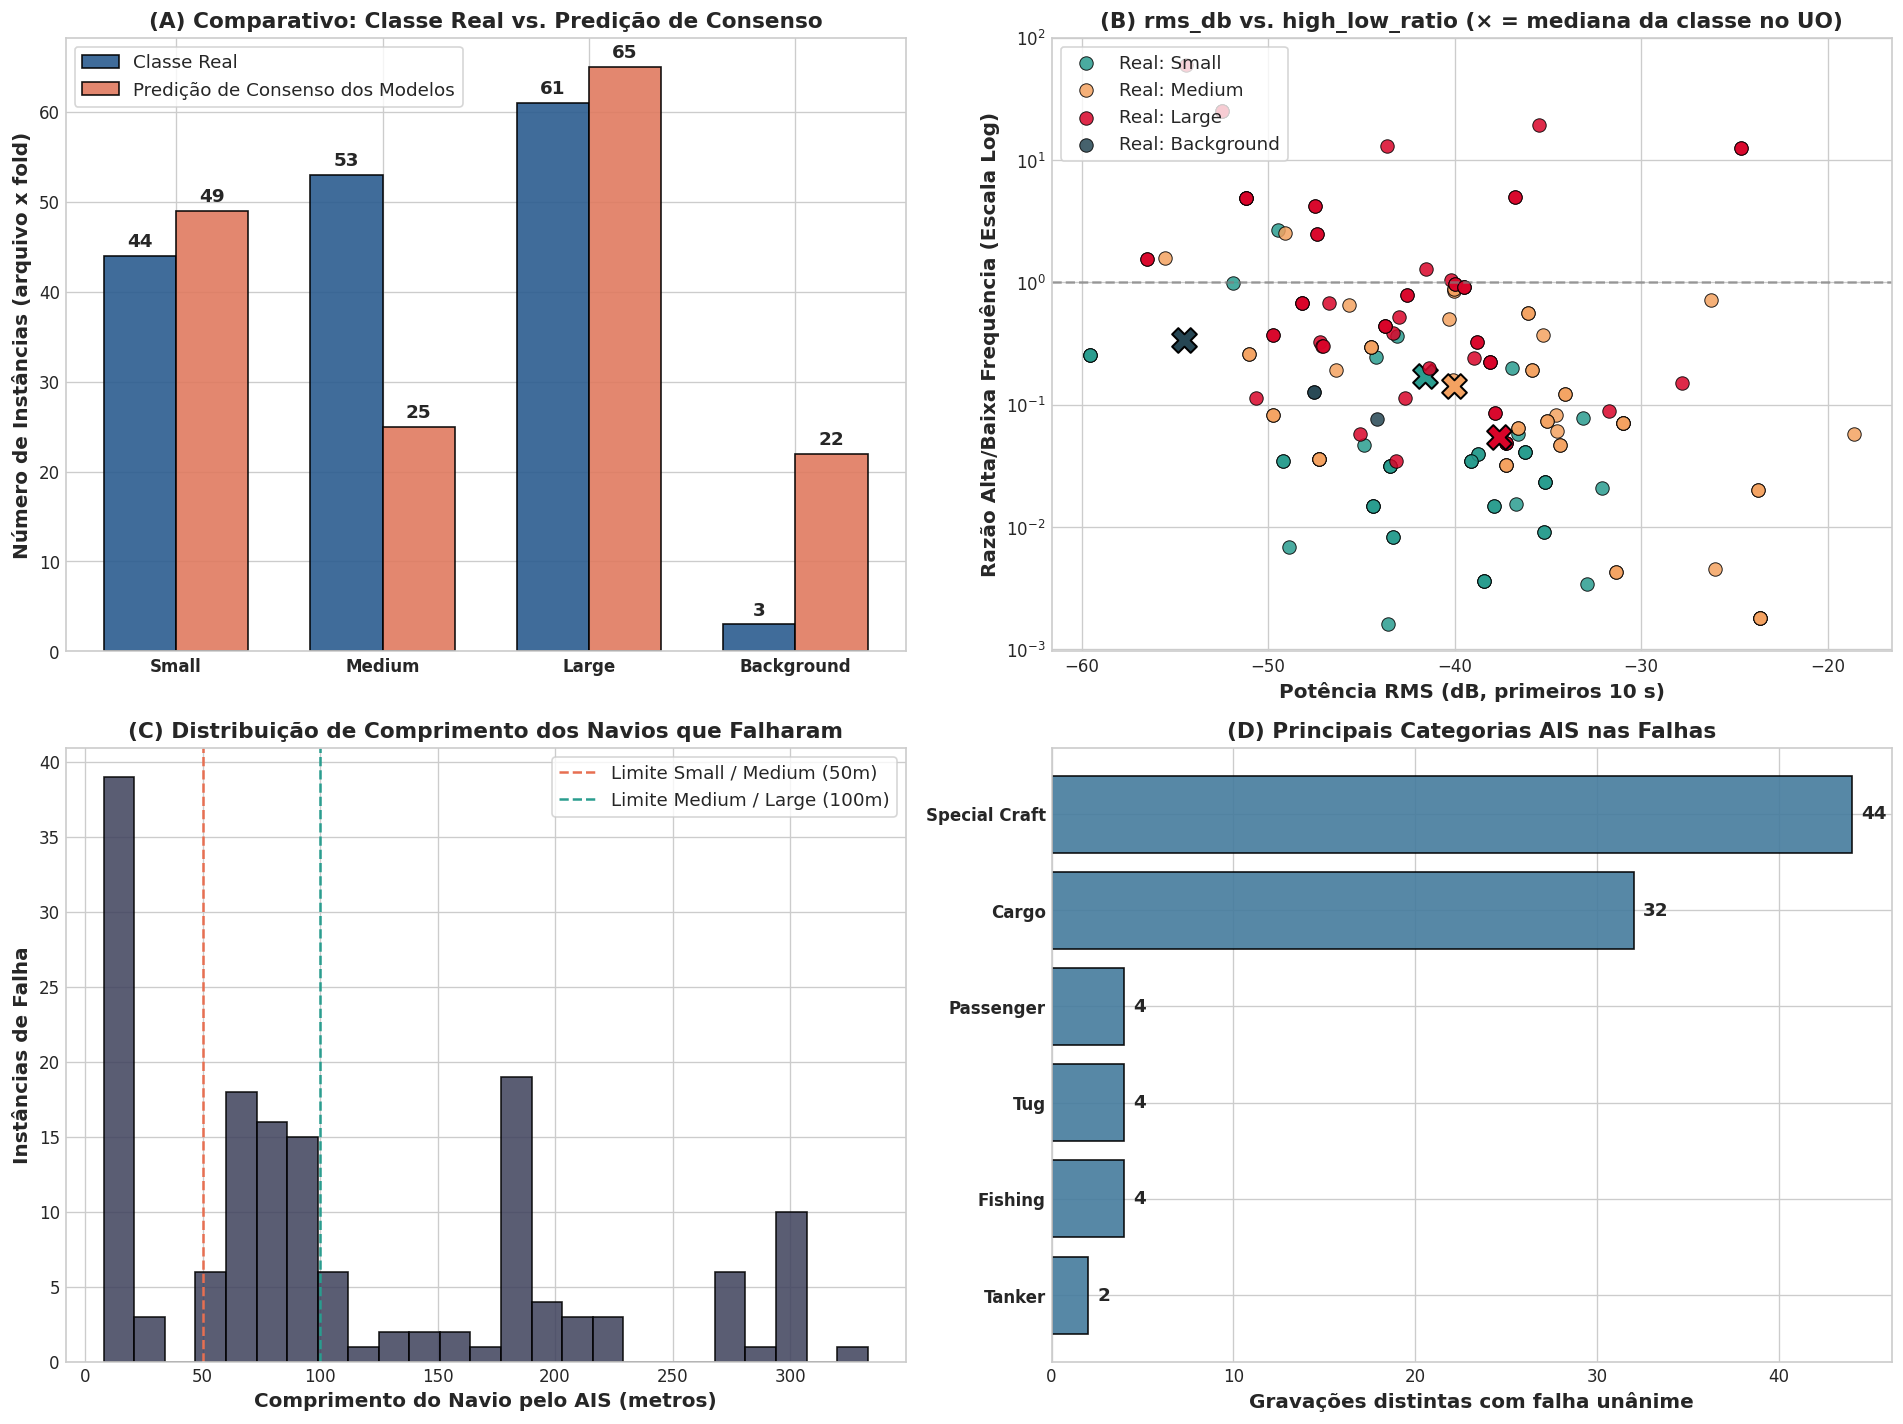

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Gráfico de Barras: Classes Reais vs. Predições de Consenso
classes = ['Small', 'Medium', 'Large', 'Background']
true_counts = [len(df_fail[df_fail['classe_real'] == c]) for c in classes]
pred_counts = [len(df_fail[df_fail['predicao_dominante'] == c]) for c in classes]

x = np.arange(len(classes))
w = 0.35
axes[0, 0].bar(x - w/2, true_counts, w, label='Classe Real', color='#2b5c8f', alpha=0.9, edgecolor='black')
axes[0, 0].bar(x + w/2, pred_counts, w, label='Predição de Consenso dos Modelos', color='#e07a5f', alpha=0.9, edgecolor='black')
axes[0, 0].set_xticks(x)
axes[0, 0].set_xticklabels(classes, fontweight='bold')
axes[0, 0].set_ylabel('Número de Instâncias (arquivo x fold)', fontweight='bold')
axes[0, 0].set_title('(A) Comparativo: Classe Real vs. Predição de Consenso', fontweight='bold')
axes[0, 0].legend(frameon=True, facecolor='white')
for i in range(len(classes)):
    axes[0, 0].text(x[i] - w/2, true_counts[i] + 1.0, str(true_counts[i]), ha='center', fontweight='bold')
    axes[0, 0].text(x[i] + w/2, pred_counts[i] + 1.0, str(pred_counts[i]), ha='center', fontweight='bold')

# 2. Dispersão: high_low_ratio vs. rms_db (+ medianas de cada classe no UO)
color_map = {'Large': '#d90429', 'Medium': '#f4a261', 'Small': '#2a9d8f', 'Background': '#264653'}
med = G.class_medians()
for c in classes:
    sub = df_fail[df_fail['classe_real'] == c]
    axes[0, 1].scatter(sub['rms_db'], sub['high_low_ratio'], label=f'Real: {c}', color=color_map[c],
                       alpha=0.85, s=65, edgecolor='black', linewidth=0.6)
    axes[0, 1].scatter(med.loc[c, 'rms_db'], med.loc[c, 'high_low_ratio'], marker='X', s=220,
                       color=color_map[c], edgecolor='black', linewidth=1.2)
axes[0, 1].set_yscale('log')
axes[0, 1].set_xlabel('Potência RMS (dB, primeiros 10 s)', fontweight='bold')
axes[0, 1].set_ylabel('Razão Alta/Baixa Frequência (Escala Log)', fontweight='bold')
axes[0, 1].set_title('(B) rms_db vs. high_low_ratio (× = mediana da classe no UO)', fontweight='bold')
axes[0, 1].axhline(1.0, color='gray', linestyle='--', alpha=0.7)
axes[0, 1].legend(frameon=True, facecolor='white', loc='upper left')

# 3. Histograma de Comprimentos dos Navios nas Falhas
lengths = df_fail['comprimento_m'].dropna()
axes[1, 0].hist(lengths, bins=25, color='#3d405b', alpha=0.85, edgecolor='black')
axes[1, 0].axvline(50, color='#e76f51', linestyle='--', linewidth=1.5, label='Limite Small / Medium (50m)')
axes[1, 0].axvline(100, color='#2a9d8f', linestyle='--', linewidth=1.5, label='Limite Medium / Large (100m)')
axes[1, 0].set_xlabel('Comprimento do Navio pelo AIS (metros)', fontweight='bold')
axes[1, 0].set_ylabel('Instâncias de Falha', fontweight='bold')
axes[1, 0].set_title('(C) Distribuição de Comprimento dos Navios que Falharam', fontweight='bold')
axes[1, 0].legend(frameon=True, facecolor='white')

# 4. Distribuição por Categoria de Embarcação (SHIPTYPE), por gravação distinta
types = df_fail.drop_duplicates('file_id')['tipo_geral'].str.strip().value_counts().head(6)
y_pos = np.arange(len(types))
axes[1, 1].barh(y_pos, types.values, color='#457b9d', alpha=0.9, edgecolor='black')
axes[1, 1].set_yticks(y_pos)
axes[1, 1].set_yticklabels(types.index, fontweight='bold')
axes[1, 1].invert_yaxis()
axes[1, 1].set_xlabel('Gravações distintas com falha unânime', fontweight='bold')
axes[1, 1].set_title('(D) Principais Categorias AIS nas Falhas', fontweight='bold')
for i, v in enumerate(types.values):
    axes[1, 1].text(v + 0.5, i, str(v), va='center', fontweight='bold')

plt.tight_layout()
plt.show()

## 5. Tabela Completa das 161 Instâncias com Falha Unânime

Tabela com todas as instâncias (uma linha por arquivo × fold; 93 gravações distintas). Pode ser filtrada e ordenada pelo nome do navio, classe real, comprimento ou descritores.

In [6]:
cols_full = [
    'file_id', 'fold', 'nome_navio', 'ship_id', 'classe_real', 'predicao_dominante',
    'votos_dominantes', 'empate_no_consenso', 'tipo_embarcacao', 'comprimento_m',
    'high_low_ratio', 'crest_factor', 'rms_db', 'estado_mar'
]
df_full_display = df_fail[cols_full].sort_values(['classe_real', 'nome_navio']).reset_index(drop=True)
print(f"Exibindo as primeiras 25 linhas de um total de {len(df_full_display)} instâncias:")
display(df_full_display.head(25))

Exibindo as primeiras 25 linhas de um total de 161 instâncias:


,file_id,fold,nome_navio,ship_id,classe_real,predicao_dominante,votos_dominantes,empate_no_consenso,tipo_embarcacao,comprimento_m,high_low_ratio,crest_factor,rms_db,estado_mar
0,1487,1,-,-,Background,Small,13,False,-,NaN,0.127026,3.863938,-47.568092,5.0
1,1607,1,-,-,Background,Large,12,False,-,NaN,0.076197,2.828243,-44.160194,3.0
2,1487,4,-,-,Background,Small,10,False,-,NaN,0.127026,3.863938,-47.568092,5.0
3,1190,2,ANTOFAGASTA EXPRESS,28,Large,Small,10,False,Container Ship,224.0,0.112696,13.573980,-42.655670,3.0
4,1032,6,APALOS,29,Large,Small,7,False,General Cargo,146.0,0.058024,6.635966,-45.070007,1.0
5,895,3,ARC RESOLVE,34,Large,Medium,15,False,Vehicles Carrier,199.0,0.049092,4.404443,-37.231937,3.0
6,895,4,ARC RESOLVE,34,Large,Medium,16,False,Vehicles Carrier,199.0,0.049092,4.404443,-37.231937,3.0
7,895,7,ARC RESOLVE,34,Large,Medium,14,False,Vehicles Carrier,199.0,0.049092,4.404443,-37.231937,3.0
8,481,6,BALTIMORE HIGHWAY,47,Large,Medium,8,False,Vehicles Carrier,180.0,2.475468,6.353209,-47.386204,1.0
9,481,8,BALTIMORE HIGHWAY,47,Large,Medium,9,False,Vehicles Carrier,180.0,2.475468,6.353209,-47.386204,1.0


## 6. Conclusões

1. **O SP de 97,70% do Super-Oráculo não é um teto físico:**
   * É a fração de áudios em que *algum* de 16 especialistas acerta, escolhido com o rótulo. Com 16 tentativas, preditores aleatórios já chegariam a 99,00%, e erros independentes dariam 99,996%. O valor observado, abaixo dessas referências, indica erros **correlacionados** entre os especialistas, e não um limite imposto pela física do sinal.
   * As 161 instâncias (2,52%) em que todos erram vêm de 93 gravações; a mesma gravação costuma reaparecer em vários folds. Elas mostram onde os 16 especialistas concordam no erro, mas não provam que essas gravações sejam "inclassificáveis".
2. **Comprimento AIS vs. assinatura acústica (hipótese):**
   * As classes são definidas por comprimento (< 50 m, 50–100 m, > 100 m). Nos grupos 2 e 4, embarcações de 8–48 m (principalmente Pilot Vessel) e de 58–89 m (principalmente Offshore Supply Ship) foram classificadas como LARGE. Isso é compatível com a hipótese de que o comprimento nem sempre se reflete na assinatura acústica, mas os dados disponíveis não permitem testá-la (não há potência de máquina, rotação ou regime de operação).
3. **Relação com o Gating (Notebook 24):**
   * Os sistemas de gating sem vazamento ficam em SP 65,41 ± 2,00 (H-MoE especializado) e 64,55 ± 1,70 (H-MoE automático), contra 66,24 ± 1,78 do MLP-LOFAR isolado (F-test 5×2cv: p = 0,67 e p = 0,48). Nenhum deles se aproxima do Super-Oráculo, e a distância entre eles e o oráculo não deve ser lida como "espaço a ser conquistado": boa parte dela vem do próprio mecanismo do oráculo.